# bending_waves: a spiral bending wave launched at a satellite's vertical resonance (epi_int_3d)

A self-gravitating ring of uniform surface density σ ≈ 4×10⁻⁸, 270 circular streamlines of 32 particles spanning
1 ≤ r ≤ 1.004 (ring mass 10⁻⁹, no viscosity), under a vertical Fourier satellite (`fast/satellite.py`). Its m = 2
inner vertical resonance is at r_V = 1.0032, 80% of the way across the ring. The satellite (i_s = 0.01, mass
2.5×10⁻⁷) is switched on at full mass at t = 0, and the run lasts 3500 orbits, stopping before the wave front reaches the
ring's inner edge.

Expectations (notes/equations.md B5–B10, B13; notes/phase2c/bending_wave_theory.md; Shu 1984):

1. Near r_V the ring's vertical displacement is Z = Re[h(x) e^{iχ}], where χ = mθ − (m+1)λ_s + Ω_s is the forcing's
   phase and x = (r − r_V)/r_V. Once established, h is the exact forced solution B8 (the paper's Eqn. 27): the
   forced response L_V/x outside r_V, and inside it a trailing spiral bending wave of constant amplitude
   |Z_w| = A_V(r_V/Gσ𝒟)^{1/2} (B8) and wavelength 4π²Gσ/(𝒟|x|) (B7).
2. The wave propagates inward at the group velocity πGσ/ν (B10), so it fills the ring inside r_V gradually.
3. The satellite's torque on the ring, which the simulated z sets, is T = −π²mσr_V²A_V²/𝒟 (B9).
4. Shu's theory is for an infinite, continuous sheet, while the ring is a finite lattice of streamlines. Both
   weaken the restoring force of the wave (B13), which shortens its wavelength by a few percent.

Make the output with `uv run python tools/run_simulations.py tests/bending_waves` (about 3 minutes). Section 7 also
uses two optional runs at higher resolution, made by the commands given there.

In [1]:
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from vertical_analysis import load3d, simulated_h, bending_wave, ring_sigma, satellite_torque, wave_wavenumber, nu_a
plt.rcParams.update({'font.size': 13})
p, o = load3d('.')
sigma = ring_sigma(p)
sat, x, h = simulated_h(p, o, -1)
A_V = sat.mass_final*sat.A_V_per_mass
D = sat.D_V
orbits = o['times']/(2*np.pi)
Z_w = A_V*np.sqrt(sat.r_V/(sigma*D))
x_in = (1 - sat.r_V)/sat.r_V
nu_V = nu_a(p['J2'], p['Rp'], sat.r_V)
for k in ('number_of_streamlines', 'particles_per_streamline', 'radial_width', 'total_ring_mass', 'dt', 'J2', 'Rp'):
    print(k, '=', p[k])
for k, v in sat.summary().items():
    print(k, '=', v)
print(f'sigma = {sigma:.4g}, resonance zone eps^1/2 = {np.sqrt(2*np.pi*sigma/(sat.r_V*D)):.3g}')
print(f'wave amplitude |Z_w| = {Z_w:.4g}, its largest |k Z_w| (inner edge) = {D*abs(x_in)/(2*np.pi*sigma)*Z_w:.3f}')
print(f'the front reaches the inner edge after {abs(x_in)*nu_V*sat.r_V/(np.pi*sigma)/(2*np.pi):.0f} orbits; '
      f'the run lasts {orbits[-1]:.0f}')

number_of_streamlines = 270
particles_per_streamline = 32
radial_width = 0.004
total_ring_mass = 1e-09
dt = 0.5
J2 = 0.01
Rp = 0.5
resonance = vertical
m = 2
mass_final = 2.5e-07
time_grow = -1.0
r = 2.090314689118
t = 0.0
inclination = 0.01
node = 0.0
Omega_a = 0.3310310834683986
nu_a = 0.3313148218226014
Omega_p = 0.4966884943796993
r_V = 1.003200000000231
beta_V = 0.4799277377816865
b_32 = 1.3708030261394069
A_V_per_mass = 0.0015686343245257211
A_V_final = 3.9215858113143026e-10
D_V = 2.9750876645170856
sigma = 3.971e-08, resonance zone eps^1/2 = 0.000289
wave amplitude |Z_w| = 1.143e-06, its largest |k Z_w| (inner edge) = 0.043
the front reaches the inner edge after 4086 orbits; the run lasts 3498


## 1: the wave is launched at r_V and propagates inward

Each streamline's inclination, averaged over its particles, versus its fractional distance from resonance x, at six
times t in units of the wave's crossing time τ_c = Δr/c_g, where Δr = r_V − 1 is the distance from resonance to
the ring's inner edge and c_g = πGσ/ν is the wave's group speed (B10). The red curve is linear theory's
inclination i = |h|/r, where h is Shu (1984)'s steady forced solution B8 (the
paper's Eqn. 27); the particles near r_V oscillate at ω_D ≈ ν, so their inclination is |h|/r to within 0.3%. The
dotted lines mark the front expected at each time, x_f = −c_g t/r_V.

Switching the satellite on at full mass also starts a free vertical oscillation everywhere. At first every streamline
moves as a massless particle would: through 100 orbits the simulated z follows the exact massless solution (B11, with
the satellite at full mass from t = 0) to within 3% across the whole ring, which is why the earliest inclinations are
nearly flat. Then the ring's self-gravity takes over: the response near r_V settles onto B8, and the wave it launches
propagates inward behind the expected front, carrying the free disturbance at resonance with it. A small residue of
that disturbance remains ahead of the front. (Growing the satellite over 160 orbits instead gives the same wave, about
160 orbits later, with a slightly smaller front overshoot and residue.)

c_g = 1.247e-07, Delta_r = 0.0032, tau_c = 2.567e+04 = 4086 orbits; the run lasts 0.86 tau_c


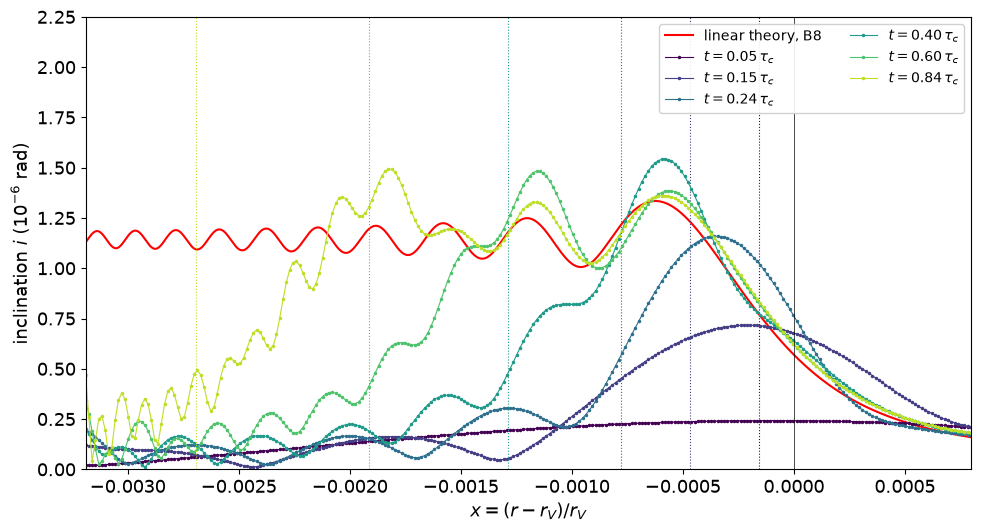

In [2]:
c_g = np.pi*sigma/nu_V                                                  #the wave's group speed (B10)
Delta_r = sat.r_V - 1.0                                                 #from resonance to the inner edge
tau_c = Delta_r/c_g                                                     #the wave's crossing time
print(f'c_g = {c_g:.4g}, Delta_r = {Delta_r:.4g}, tau_c = {tau_c:.4g} = {tau_c/(2*np.pi):.0f} orbits; '
      f'the run lasts {o["times"][-1]/tau_c:.2f} tau_c')
picks = [0.05, 0.15, 0.25, 0.4, 0.6, 0.85]                              #t/tau_c
fig, ax = plt.subplots(figsize=(10, 5.5))
xs = np.linspace(x.min(), x.max(), 20000)
ax.plot(xs, np.abs(bending_wave(sat, sigma, xs))/(sat.r_V*(1 + xs))/1e-6, 'r-', lw=1.5, label='linear theory, B8')
colors = plt.cm.viridis(np.linspace(0, 0.9, len(picks)))
for frac, c in zip(picks, colors):
    k = np.argmin(np.abs(o['times'] - frac*tau_c))
    xk = ((o['a'][k] - sat.r_V)/sat.r_V).mean(axis=1)
    ax.plot(xk, o['inc'][k].mean(axis=1)/1e-6, '.-', ms=3, lw=0.8, color=c,
            label=rf'$t = {o["times"][k]/tau_c:.2f}\,\tau_c$')
    ax.axvline(-c_g*(o['times'][k] - max(sat.time_grow, 0.0))/sat.r_V, color=c, lw=0.8, ls=':')
ax.axvline(0, color='k', lw=0.5)
ax.set_xlim(x.min(), x.max()); ax.set_ylim(0, 2.25)
ax.set_xlabel(r'$x = (r - r_V)/r_V$'); ax.set_ylabel(r'inclination $i$ ($10^{-6}$ rad)')
ax.legend(fontsize=10, loc='upper right', ncol=2, framealpha=0.9)
plt.tight_layout()

## Animations: the ring's height over the run

Two animations, one frame every 100 orbits, made by `uv run python animate.py` (about 10 s):

- [bending_wave.gif](https://github.com/joehahn/epi_int_3d/blob/main/tests/bending_waves/bending_wave.gif): the ring seen face-on in the frame rotating with the pattern speed Ω_p,
  where the m = 2 spiral is stationary, with the ring's width stretched radially so the wave shows. Grayscale is the
  height z in units of |Z_w|, white above the plane and black below; the red dashed circle is r_V. Each streamline's
  particles are interpolated along the streamline with a periodic spline in longitude.
- [bending_wave_lines.gif](https://github.com/joehahn/epi_int_3d/blob/main/tests/bending_waves/bending_wave_lines.gif): every 3rd streamline's particles joined by a line, z versus
  longitude in the same frame, each offset by its distance from resonance x. The z scale is the largest that keeps
  adjacent curves apart, so the wave's height is drawn at only about one curve spacing.

## 2: the ring's vertical displacement at the end

Each particle's z, against its fractional distance from resonance x and its longitude θ: the wave's two trailing
arms wind tighter inward, away from r_V (x = 0).

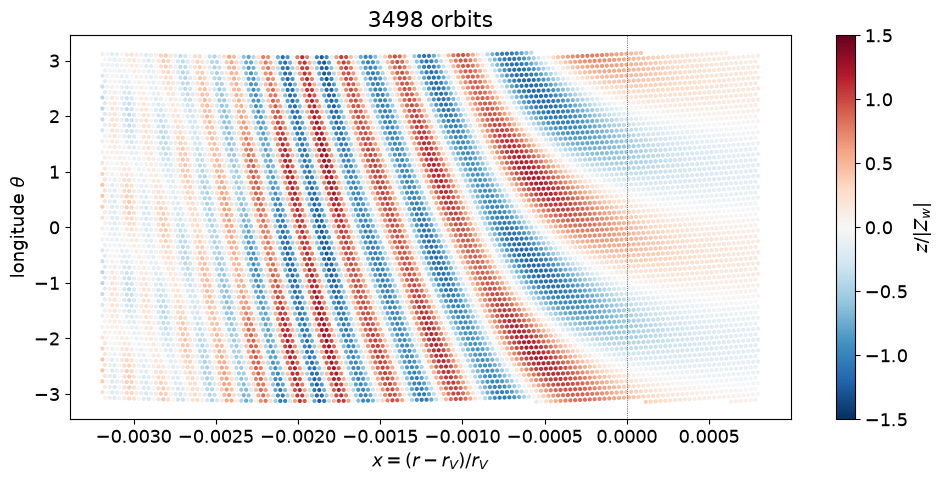

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
xx = (o['r'][-1] - sat.r_V)/sat.r_V
s = ax.scatter(xx, o['t'][-1], c=o['z'][-1]/Z_w, s=4, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
ax.axvline(0, color='k', lw=0.5, ls=':')
ax.set_xlabel(r'$x = (r - r_V)/r_V$'); ax.set_ylabel(r'longitude $\theta$')
fig.colorbar(s, label=r'$z/|Z_w|$')
ax.set_title(f'{orbits[-1]:.0f} orbits')
plt.tight_layout()

## 3: the wave's complex amplitude h versus x at three times, against B8

Each streamline's h is a least-squares fit of its particles' z = Re(h) cos χ − Im(h) sin χ. The red curve is the
exact steady solution B8; dotted lines mark the front expected from the group velocity B10, x_f = −πGσt/(ν r_V).

outside the resonance zone (x > 2 eps^1/2): max |h - B8|/|B8| = 0.149
behind the front (-0.0018 < x < -0.0004): median |h - L_V/x| / |Z_w| = 1.029


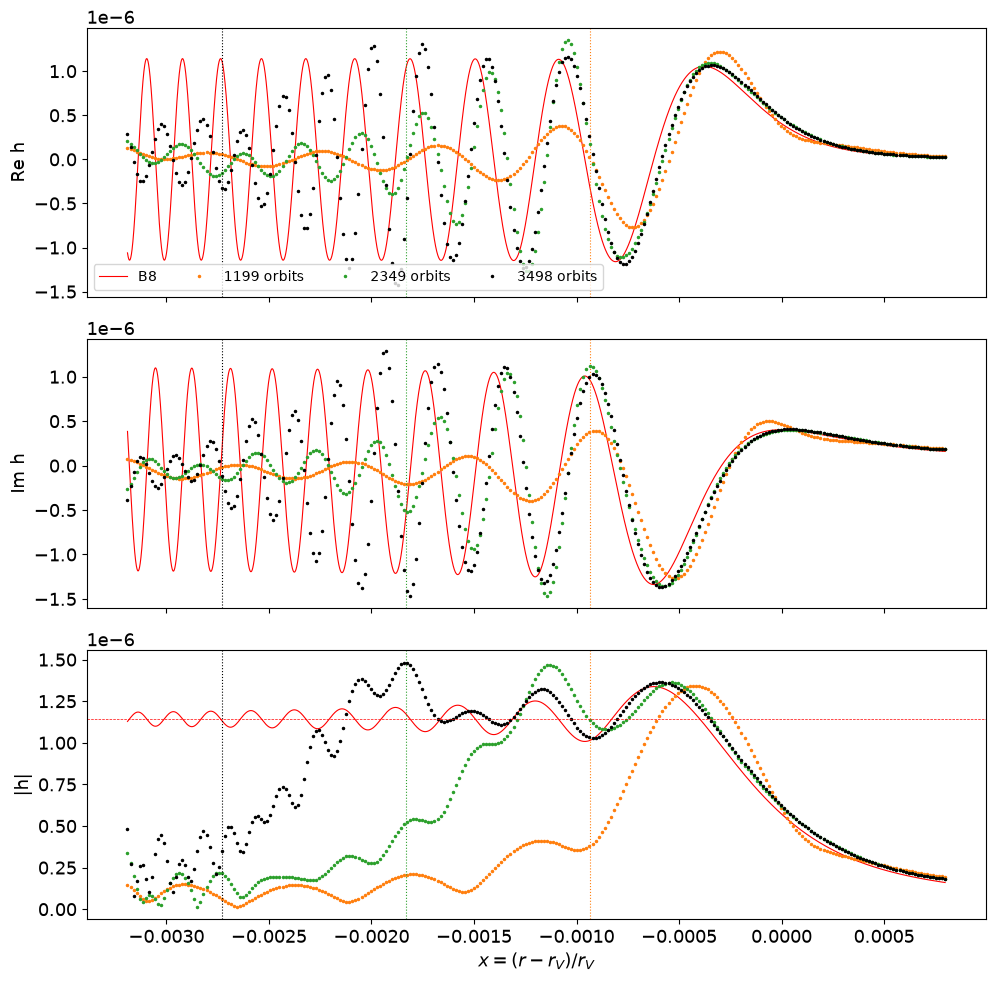

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
xs = np.linspace(x.min(), x.max(), 20000)
ht = bending_wave(sat, sigma, xs)
for a, f, lab in zip(axs, (np.real, np.imag, np.abs), ('Re h', 'Im h', '|h|')):
    a.plot(xs, f(ht), 'r-', lw=0.8, label='B8' if lab == 'Re h' else None)
    a.set_ylabel(lab)
for k, c in ((len(orbits)//3, 'C1'), (2*len(orbits)//3, 'C2'), (len(orbits) - 1, 'k')):
    _, xk, hk = simulated_h(p, o, k)
    xf = -np.pi*sigma*(o['times'][k] - max(sat.time_grow, 0.0))/(nu_V*sat.r_V)
    for a, f in zip(axs, (np.real, np.imag, np.abs)):
        a.plot(xk, f(hk), '.', ms=3, color=c, label=f'{orbits[k]:.0f} orbits' if f is np.real else None)
        a.axvline(xf, color=c, lw=0.8, ls=':')
axs[2].axhline(Z_w, color='r', lw=0.5, ls='--')
axs[0].legend(fontsize=10, ncol=4, loc='lower left')
axs[2].set_xlabel(r'$x = (r - r_V)/r_V$')
plt.tight_layout()
f_V = 1j*A_V/(D*x)
outside = x > 2*np.sqrt(2*np.pi*sigma/(sat.r_V*D))
hB8 = bending_wave(sat, sigma, x)
print(f'outside the resonance zone (x > 2 eps^1/2): max |h - B8|/|B8| = {(np.abs(h - hB8)/np.abs(hB8))[outside].max():.3f}')
behind = (x < -0.0004) & (x > -0.0018)
print(f'behind the front (-0.0018 < x < -0.0004): median |h - L_V/x| / |Z_w| = {np.median(np.abs(h - f_V)[behind])/Z_w:.3f}')

## 4: the wave's wavenumber versus x

The local wavenumber is the radial derivative of the phase of the wave part h − L_V/x, from the simulation and from
B8. It is compared with three dispersion relations (`wave_wavenumber`, B13): the continuum's 𝒟|x| = 2πGσk (B7, which
B8 also assumes), the lattice of streamlines spaced Δ, 𝒟|x| = X(kΔ), and that lattice cut off at the ring's edges,
𝒟|x| = X(kΔ) − 2Gσ(1/d_in + 1/d_out), since the ring lacks the pull of the streamlines beyond its edges.

-0.0018 < x < -0.0004: simulated k / continuum - 1: median +0.073, rms 0.089
-0.0018 < x < -0.0004: simulated k / lattice - 1: median +0.037, rms 0.064
-0.0018 < x < -0.0004: simulated k / lattice + edges - 1: median +0.010, rms 0.036


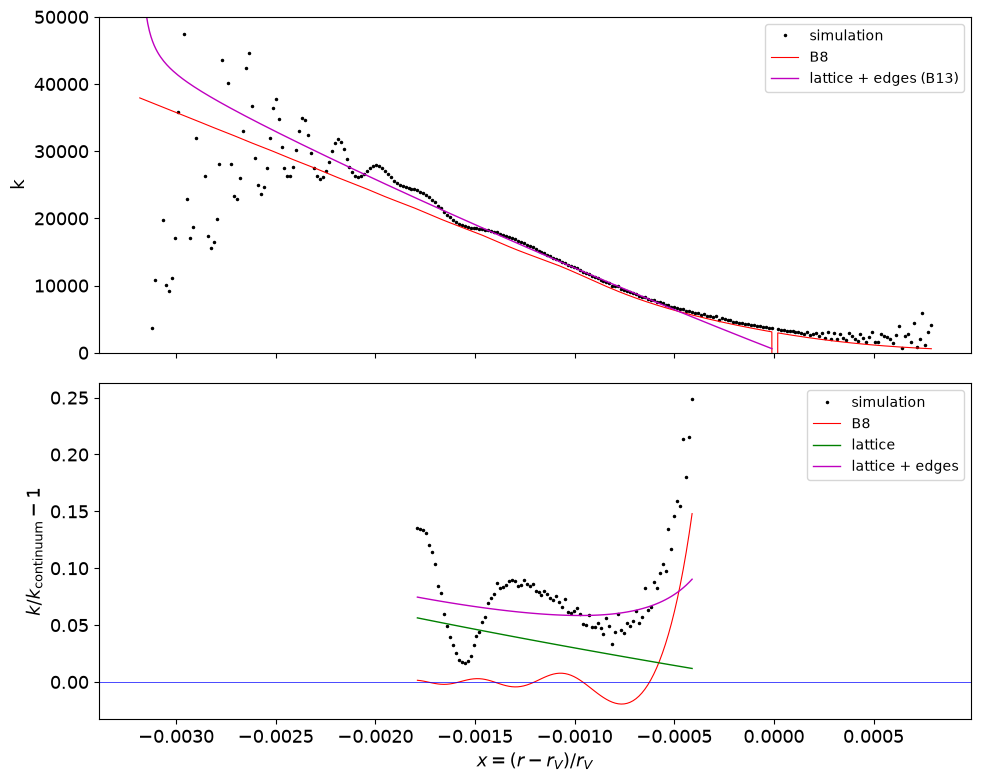

In [5]:
xm = 0.5*(x[1:] + x[:-1])
kr = lambda w: np.angle(w[1:]/w[:-1])/np.diff(x)/sat.r_V
k_sim, k_B8 = kr(h - f_V), kr(hB8 - f_V)
sel = (xm < -0.0004) & (xm > -0.0018)
k_cont, k_lat, k_edge = wave_wavenumber(p, sat, xm[sel])
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axs[0].plot(xm, k_sim, 'k.', ms=3, label='simulation')
axs[0].plot(xm, k_B8, 'r-', lw=0.8, label='B8')
xs2 = np.linspace(x.min(), -1e-5, 400)
axs[0].plot(xs2, wave_wavenumber(p, sat, xs2)[2], 'm-', lw=1, label='lattice + edges (B13)')
axs[0].set_ylim(0, 5e4); axs[0].set_ylabel('k'); axs[0].legend(fontsize=10)
axs[1].plot(xm[sel], k_sim[sel]/k_cont - 1, 'k.', ms=3, label='simulation')
axs[1].plot(xm[sel], k_B8[sel]/k_cont - 1, 'r-', lw=0.8, label='B8')
axs[1].plot(xm[sel], k_lat/k_cont - 1, 'g-', lw=1, label='lattice')
axs[1].plot(xm[sel], k_edge/k_cont - 1, 'm-', lw=1, label='lattice + edges')
axs[1].axhline(0, color='b', lw=0.5)
axs[1].set_ylabel(r'$k/k_{\rm continuum} - 1$'); axs[1].set_xlabel(r'$x = (r - r_V)/r_V$'); axs[1].legend(fontsize=10)
plt.tight_layout()
for name, kk in (('continuum', k_cont), ('lattice', k_lat), ('lattice + edges', k_edge)):
    print(f'-0.0018 < x < -0.0004: simulated k / {name} - 1: median {np.median(k_sim[sel]/kk - 1):+.3f}, '
          f'rms {np.sqrt(np.mean((k_sim[sel]/kk - 1)**2)):.3f}')

## 5: the satellite's torque on the ring

The torque that the satellite's resonant potential A_V z sin χ exerts on the simulated ring, −Σ μ m A_V z cos χ
summed over particles (B9's integrand), accumulated inward from the outer edge, against the same sum over B8's h; and
the ring's total over time, against B9, T = −π²mσr_V²A_V²/𝒟. fast/satellite.py applies only the satellite's vertical
pull, so the ring's own angular momentum does not change.

total torque at the end: -4.144e-26, B9: -4.078e-26, ratio 1.016; mean over the last half of the run: 0.997


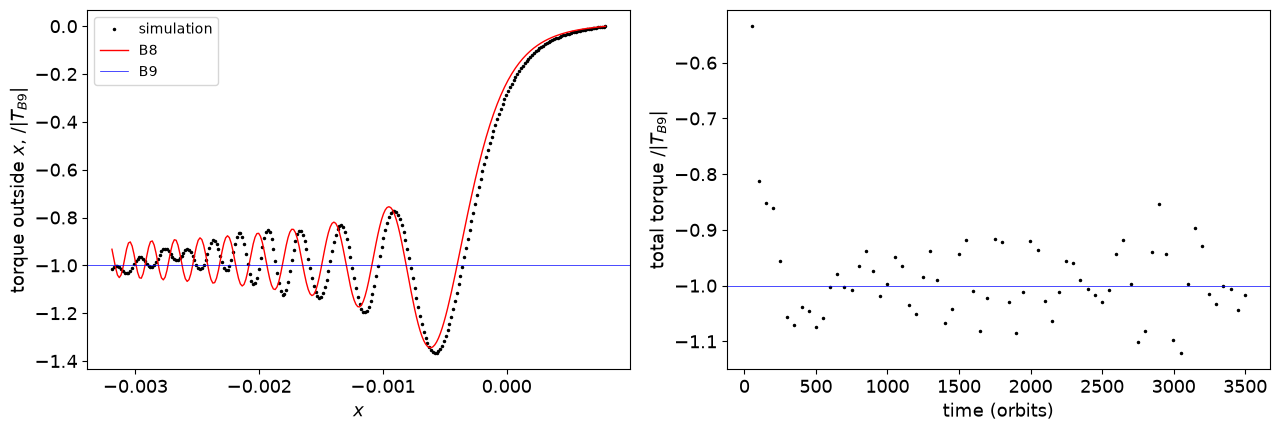

In [6]:
T_B9 = -np.pi**2*sat.m*sigma*sat.r_V**2*A_V**2/D
T = satellite_torque(p, o, -1)
mu_s = p['total_ring_mass']/p['number_of_streamlines']
T_B8 = -sat.m*A_V*mu_s*hB8.real/2
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(x, np.cumsum(T[::-1])[::-1]/abs(T_B9), 'k.', ms=3, label='simulation')
axs[0].plot(x, np.cumsum(T_B8[::-1])[::-1]/abs(T_B9), 'r-', lw=1, label='B8')
axs[0].axhline(-1, color='b', lw=0.5, label='B9')
axs[0].set_xlabel(r'$x$'); axs[0].set_ylabel(r'torque outside $x$, $/|T_{B9}|$'); axs[0].legend(fontsize=10)
axs[0].xaxis.set_major_locator(plt.MaxNLocator(5))
Tt = np.array([satellite_torque(p, o, k).sum() for k in range(len(orbits))])
axs[1].plot(orbits, Tt/abs(T_B9), 'k.', ms=3)
axs[1].axhline(-1, color='b', lw=0.5)
axs[1].set_xlabel('time (orbits)'); axs[1].set_ylabel(r'total torque $/|T_{B9}|$')
plt.tight_layout()
print(f'total torque at the end: {T.sum():.4g}, B9: {T_B9:.4g}, ratio {T.sum()/T_B9:.3f}; '
      f'mean over the last half of the run: {Tt[len(Tt)//2:].mean()/T_B9:.3f}')

## 6: in-plane motion

The streamlines should stay circular and in place: the satellite pulls only vertically, and the ring's in-plane
self-gravity is weak.

In [7]:
dr = np.abs(o['r'] - o['r'][0]).max()
print(f'largest radial excursion of any particle: {dr:.2e}, '
      f'streamline spacing {p["radial_width"]/(p["number_of_streamlines"] - 1):.2e}; '
      f'crossing: {o["monitor"].get("streamline_crossing_timestep")}')

largest radial excursion of any particle: 1.77e-08, streamline spacing 1.49e-05; crossing: None


## 7: resolution

Two optional runs, made from this folder by
```
uv run python ../../fast/epi_int_3d.py -m '{"particles_per_streamline": 64, "number_of_particles": 17280, "output_folder": "output_np64"}'
uv run python ../../fast/epi_int_3d.py -m '{"number_of_streamlines": 540, "number_of_particles": 17280, "output_folder": "output_ns540"}'
```
(about 3 and 11 minutes). With twice the particles per streamline nothing should change. With twice the
streamlines, the lattice's part of the wavenumber excess should halve, while the edges' part stays.

In [8]:
for folder in ('output', 'output_np64', 'output_ns540'):
    if not Path(folder).exists():
        print(folder, 'not found: skipped')
        continue
    pv, ov = load3d('.', output_folder=folder,
                    modified_params=None if folder == 'output' else
                    {'particles_per_streamline': 64, 'number_of_particles': 17280} if folder == 'output_np64' else
                    {'number_of_streamlines': 540, 'number_of_particles': 17280})
    _, xv, hv = simulated_h(pv, ov, -1)
    fv = 1j*A_V/(D*xv)
    xmv = 0.5*(xv[1:] + xv[:-1])
    kv = np.angle((hv - fv)[1:]/(hv - fv)[:-1])/np.diff(xv)/sat.r_V
    s = (xmv < -0.0004) & (xmv > -0.0018)
    kc, kl, ke = wave_wavenumber(pv, sat, xmv[s])
    b = (xv < -0.0004) & (xv > -0.0018)
    print(f'{folder:13s} {pv["number_of_streamlines"]} x {pv["particles_per_streamline"]}: median k/k - 1: '
          f'continuum {np.median(kv[s]/kc - 1):+.3f}, lattice {np.median(kv[s]/kl - 1):+.3f}, '
          f'lattice + edges {np.median(kv[s]/ke - 1):+.3f};  median |wave|/|Z_w| {np.median(np.abs(hv - fv)[b])/Z_w:.3f};  '
          f'torque/B9 {satellite_torque(pv, ov, -1).sum()/T_B9:.3f}')

output        270 x 32: median k/k - 1: continuum +0.073, lattice +0.037, lattice + edges +0.010;  median |wave|/|Z_w| 1.029;  torque/B9 1.016


output_np64   270 x 64: median k/k - 1: continuum +0.073, lattice +0.039, lattice + edges +0.009;  median |wave|/|Z_w| 1.029;  torque/B9 1.013
output_ns540 not found: skipped



## Summary

Once established, the simulated wave matches Shu (1984)'s linear theory. Behind the front its amplitude is within 3%
of B8's |Z_w| (median), and the satellite's torque on the ring reaches B9 within about 300 orbits, as soon as the
resonance zone is set up, overshoots by up to 7%, and from about 600 orbits on stays within 2% of it. The front advances at about the group velocity B10, spread
by dispersion.

The wavenumber is 7% above the continuum's B7 (median), because the ring is a finite lattice of streamlines, not an
infinite sheet: the lattice's spacing and the ring's edges both weaken the wave's restoring force (B13), and with
both allowed for the excess drops to 1%, with a ±4% ripple. The code's ring gravity matches B13 to 0.2% on a
corrugated ring (`tests/test_kernels.py`). Doubling the particles per streamline changes nothing. Doubling the
streamlines (Section 7) cuts the excess over the continuum from 7.2% to 4.9%, as the lattice's part shrinks while
the edges' part stays; against the lattice with edges it is then 0.4%, and the amplitude is within 1.3% of B8's.

Outside the resonance zone, the forced response is 10–15% above B8. The outer edge is only 2×10⁻⁴ away, and the
infinite-sheet theory includes ring material beyond it; that is the likely cause, but B13 is for the wave region and
this has not been quantified.
